In [24]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from keras.models import Model
from keras.layers import Input, Dense
from keras.regularizers import l1
from keras.datasets import mnist

In [25]:
(xtrain, ytrain), (xtest, ytest) = mnist.load_data()

In [26]:
xtrain = xtrain / 255.0
xtest = xtest / 255.0

In [36]:
#  Flatten Images (28 x 28 = 784)
xtrain = xtrain.reshape(-1, 784)
xtest = xtest.reshape(-1, 784)
print(xtrain.shape)

(60000, 784)


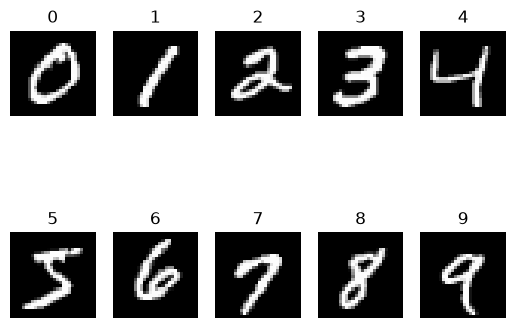

In [37]:
for i in range(10):

    n = np.where(ytrain == i)[0][0]

    plt.subplot(2,5,i+1)
    plt.imshow(xtrain[n].reshape(28,28), cmap='gray')
    plt.title(ytrain[n])
    plt.axis('off')

plt.show()

In [38]:
input_img = Input(shape=(784,))

encoded = Dense(128, activation = 'relu', activity_regularizer=l1(0.00001))(input_img)

decoded = Dense(784, activation = 'sigmoid')(encoded)

autoencoder = Model(input_img, decoded)

In [39]:
autoencoder.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy'
)
autoencoder.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 201,616 (787.56 KB)

 Trainable params: 201,616 (787.56 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# 8. Train Model
history = autoencoder.fit(
    xtrain,
    xtrain,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(xtest,xtest)
)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2151 - val_loss: 0.1368
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1198 - val_loss: 0.1049
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0989 - val_loss: 0.0916
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0888 - val_loss: 0.0845
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0831 - val_loss: 0.0803
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0796 - val_loss: 0.0776
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0773 - val_loss: 0.0758
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0756 - val_loss: 0.0744
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0744 - val_loss: 0.0734
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0735 - val_loss: 0.0727


In [42]:
reconstructed = autoencoder.predict(xtest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step


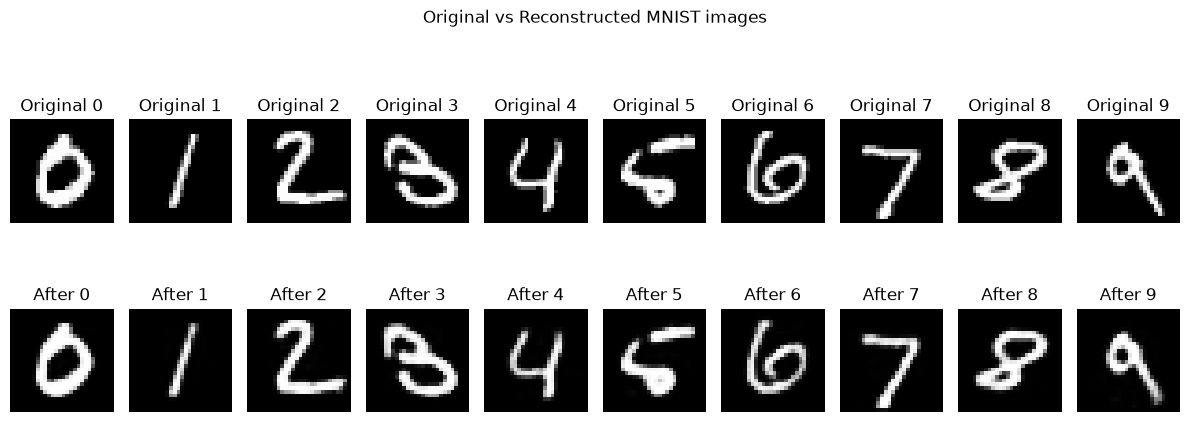

In [49]:
plt.figure(figsize=(12,5))

for i in range(10):
    n = np.where(ytest == i)[0][0]

    plt.subplot(2, 10, i+1)
    plt.imshow(xtest[n].reshape(28,28), cmap='gray')
    plt.title("Original "+str(i))
    plt.axis('off')

    plt.subplot(2, 10, i+11)
    plt.imshow(reconstructed[n].reshape(28,28), cmap='gray')
    plt.title("After "+str(i))
    plt.axis('off')

plt.suptitle("Original vs Reconstructed MNIST images")
plt.tight_layout()
plt.show()

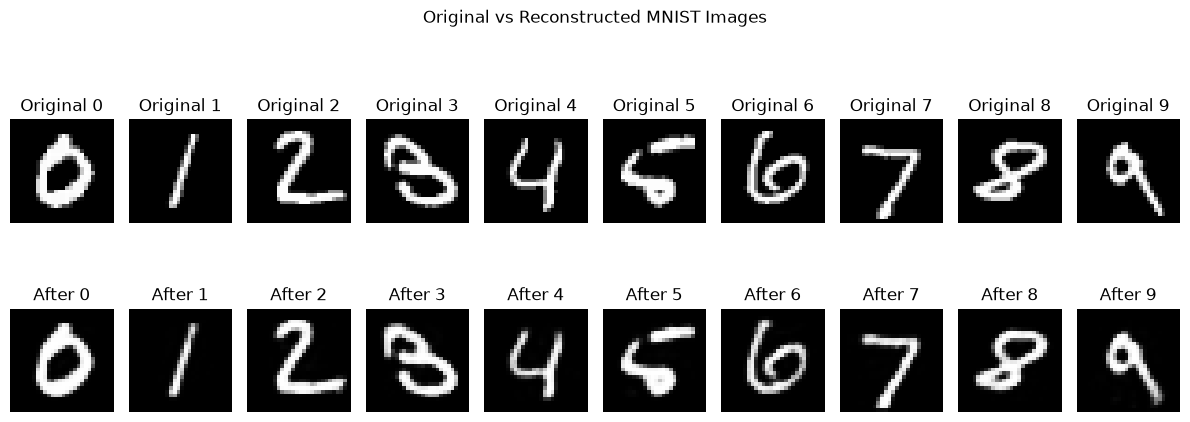

In [48]:
# 10. Display Original and Reconstructed Images
plt.figure(figsize=(12, 5))

for i in range(10):

    n = np.where(ytest == i)[0][0]

    # Original Image
    plt.subplot(2, 10, i + 1)
    plt.imshow(xtest[n].reshape(28, 28), cmap='gray')
    plt.title("Original " + str(i))
    plt.axis('off')

    # Reconstructed Image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[n].reshape(28, 28), cmap='gray')
    plt.title("After " + str(i))
    plt.axis('off')

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()
